In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn


In [2]:
import pandas as pd

In [3]:
import numpy as np

In [4]:
import matplotlib.pyplot as plt

In [5]:
import seaborn as sns

In [6]:
random_state = 272

In [7]:
np.random.seed(random_state)

In [8]:
df = pd.read_csv('USA_housing_toy.csv')

In [9]:
df.head()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
0,79545.45857,5.682861,7.009188,4.09,23086.80050,1.059034e+06,"208 Michael Ferry Apt. 674\nLaurabury, NE 3701..."
1,79248.64245,6.002900,6.730821,3.09,40173.07217,1.505891e+06,"188 Johnson Views Suite 079\nLake Kathleen, CA..."
2,61287.06718,5.865890,8.512727,5.13,36882.15940,1.058988e+06,"9127 Elizabeth Stravenue\nDanieltown, WI 06482..."
3,63345.24005,7.188236,5.586729,3.26,34310.24283,1.260617e+06,USS Barnett\nFPO AP 44820
4,59982.19723,5.040555,7.839388,4.23,26354.10947,6.309435e+05,USNS Raymond\nFPO AE 09386


In [12]:
df.isnull().sum()

Avg. Area Income                0
Avg. Area House Age             0
Avg. Area Number of Rooms       0
Avg. Area Number of Bedrooms    0
Area Population                 0
Price                           0
Address                         0
dtype: int64

In [13]:
df.describe()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price
count,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2.500000e+03
mean,68593.117818,5.980941,7.005079,3.989816,36032.881352,1.233117e+06
std,10696.969146,1.007664,1.002411,1.241848,9803.908974,3.547254e+05
min,17796.631190,2.644304,3.236194,2.000000,172.610686,3.114052e+04
25%,61461.357480,5.328918,6.311252,3.150000,29381.948903,9.937032e+05
50%,68709.189825,5.981525,7.024682,4.050000,36073.859200,1.235056e+06
75%,75868.888025,6.680616,7.687694,4.500000,42683.564510,1.467923e+06
max,107701.748400,8.991399,10.759588,6.500000,69592.040240,2.469066e+06


In [14]:
X = df[['Avg. Area Income', 'Avg. Area House Age', 'Avg. Area Number of Rooms',
               'Avg. Area Number of Bedrooms', 'Area Population']]

In [15]:
y = df['Price']

In [16]:
from sklearn.model_selection import train_test_split

In [17]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=random_state)

In [18]:
from sklearn.preprocessing import StandardScaler

In [19]:
scaler = StandardScaler()

In [20]:
X_train = scaler.fit_transform(X_train)

In [21]:
X_test = scaler.transform(X_test)

In [22]:
from sklearn.linear_model import LinearRegression

In [23]:
model = LinearRegression()

In [24]:
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [25]:
print("Intercept:", model.intercept_)

Intercept: 1231034.947415187


In [26]:
coeff_df = pd.DataFrame(model.coef_,X.columns,columns=['Coefficient'])

In [27]:
coeff_df

,Coefficient
Avg. Area Income,241166.438469
Avg. Area House Age,162093.210742
Avg. Area Number of Rooms,119105.490597
Avg. Area Number of Bedrooms,-382.808082
Area Population,148911.546167


In [28]:
print('Interpreting the coefficients:')

Interpreting the coefficients:


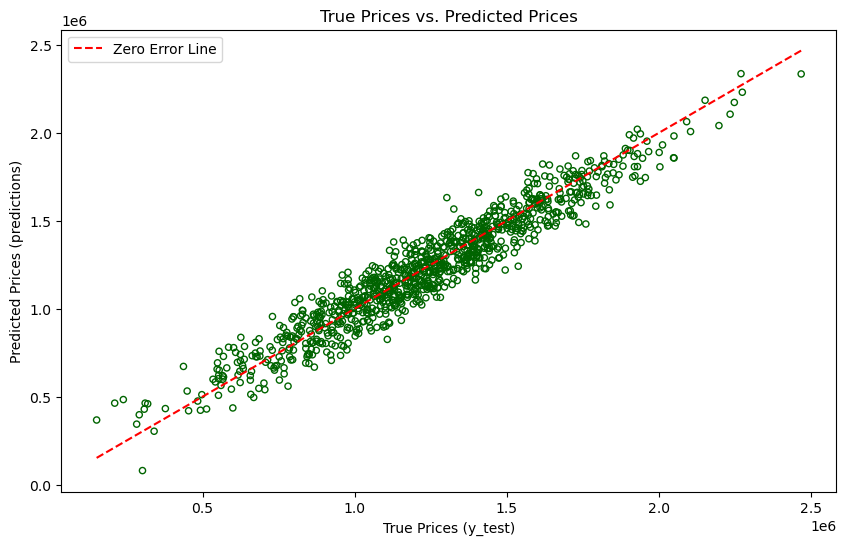

In [40]:
predictions = model.predict(X_test)
plt.figure(figsize=(10, 6))
plt.scatter(y_test, predictions, s=20, facecolors='none', edgecolors='darkgreen')
plt.xlabel("True Prices (y_test)")
plt.ylabel("Predicted Prices (predictions)")
plt.title("True Prices vs. Predicted Prices")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', label='Zero Error Line')
plt.legend()
plt.show()

In [32]:
from sklearn import metrics
print('MAE      :', metrics.mean_absolute_error(y_test, predictions))
print('MSE      :', metrics.mean_squared_error(y_test, predictions))
print('RMSE     :', np.sqrt(metrics.mean_squared_error(y_test, predictions)))
print('R² Score :', np.sqrt(metrics.r2_score(y_test, predictions)))

MAE      : 81428.75254620623
MSE      : 10159472913.275927
RMSE     : 100794.21071309566
R² Score : 0.9573954960347011
